# Step 2: exploratory data analysis. Saves every chart to figures/.

In [1]:
# Run from the project root so data/, figures/ and results/ paths work
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%matplotlib inline

In [2]:
import os
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.tsa.stattools import adfuller

from config import RAW_PATH, HORIZON

os.makedirs("figures", exist_ok=True)
prices = pd.read_csv(RAW_PATH, index_col="Date", parse_dates=True)

In [3]:
# 1. Data quality
print("Shape:", prices.shape)
print("\nMissing values before filling:\n", prices.isna().sum())
prices = prices.ffill().dropna()      # FX/index holidays differ from US stocks

Shape: (4234, 8)

Missing values before filling:
 MSFT      0
IBM       0
GOOGL     0
USDJPY    6
GBPUSD    6
SP500     0
DJIA      0
VIX       0
dtype: int64


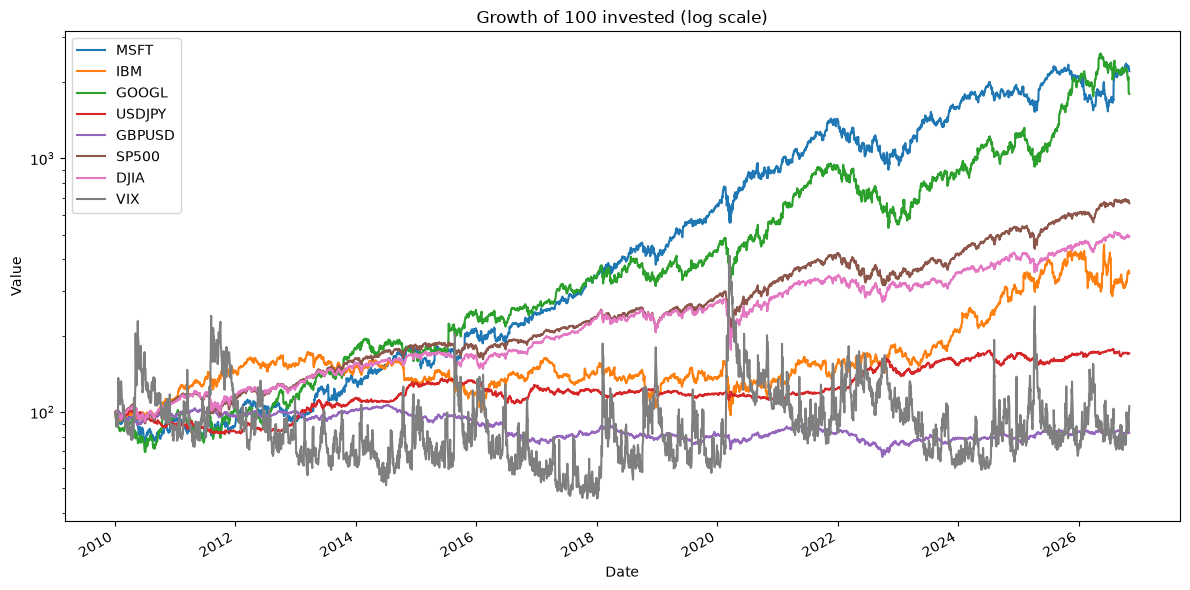

In [4]:
# 2. Prices over time (normalised to 100 so they fit on one chart)
(prices / prices.iloc[0] * 100).plot(figsize=(12, 6), logy=True)
plt.title("Growth of 100 invested (log scale)")
plt.ylabel("Value")
plt.tight_layout(); plt.savefig("figures/01_normalised_prices.png", dpi=120); plt.show()

In [5]:
# 3. Weekly log returns
weekly = np.log(prices).diff(HORIZON).iloc[::HORIZON].dropna()
print("\nSummary of weekly log returns:\n", weekly.describe().T.round(4))
print("\nSkew:\n", weekly.skew().round(2))
print("\nExcess kurtosis (fat tails if > 0):\n", weekly.kurt().round(2))


Summary of weekly log returns:
         count    mean     std     min     25%     50%     75%     max
MSFT    846.0  0.0037  0.0344 -0.1559 -0.0144  0.0060  0.0238  0.2254
IBM     846.0  0.0015  0.0359 -0.3438 -0.0154  0.0031  0.0205  0.1632
GOOGL   846.0  0.0036  0.0386 -0.1440 -0.0192  0.0059  0.0254  0.1742
USDJPY  846.0  0.0006  0.0132 -0.0571 -0.0067  0.0011  0.0083  0.0634
GBPUSD  846.0 -0.0002  0.0125 -0.0895 -0.0075 -0.0001  0.0078  0.0596
SP500   846.0  0.0023  0.0226 -0.1623 -0.0074  0.0046  0.0147  0.1041
DJIA    846.0  0.0019  0.0221 -0.1900 -0.0079  0.0041  0.0140  0.1208
VIX     846.0 -0.0002  0.1578 -0.6287 -0.0843 -0.0113  0.0736  0.9601

Skew:
 MSFT     -0.25
IBM      -1.10
GOOGL     0.03
USDJPY   -0.11
GBPUSD   -0.82
SP500    -1.15
DJIA     -1.38
VIX       0.91
dtype: float64

Excess kurtosis (fat tails if > 0):
 MSFT       4.08
IBM       12.47
GOOGL      1.84
USDJPY     2.11
GBPUSD     6.54
SP500      6.74
DJIA      11.05
VIX        4.98
dtype: float64


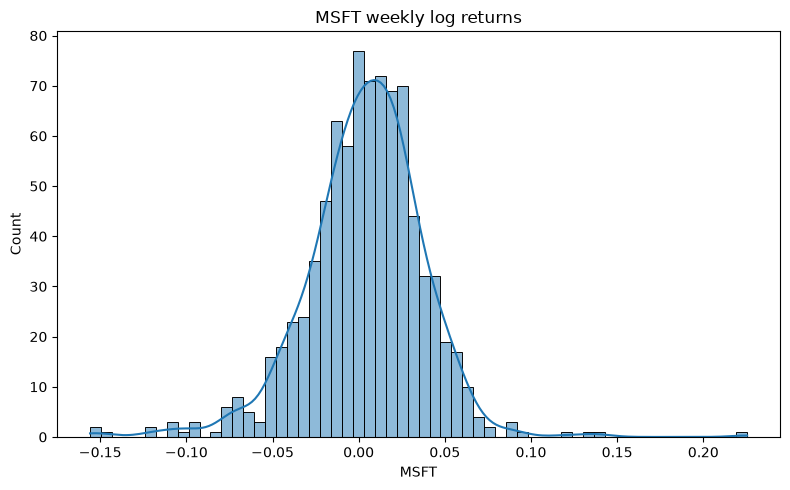

In [6]:
# 4. Distribution of the target
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(weekly["MSFT"], bins=60, kde=True, ax=ax)
ax.set_title("MSFT weekly log returns")
plt.tight_layout(); plt.savefig("figures/02_msft_return_hist.png", dpi=120); plt.show()

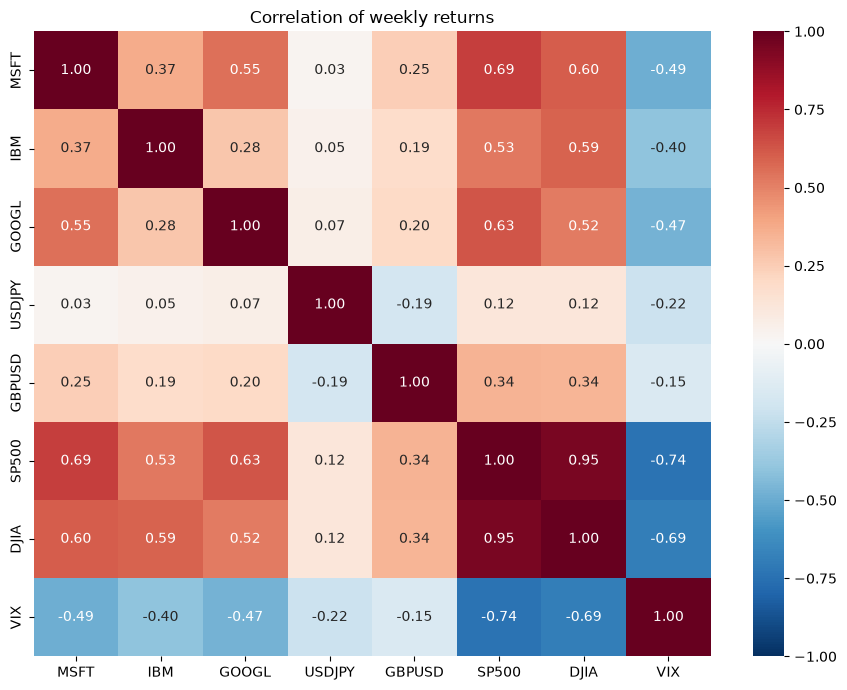

In [7]:
# 5. Correlation heatmap (the key EDA chart for this project)
plt.figure(figsize=(9, 7))
sns.heatmap(weekly.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation of weekly returns")
plt.tight_layout(); plt.savefig("figures/03_correlation_heatmap.png", dpi=120); plt.show()

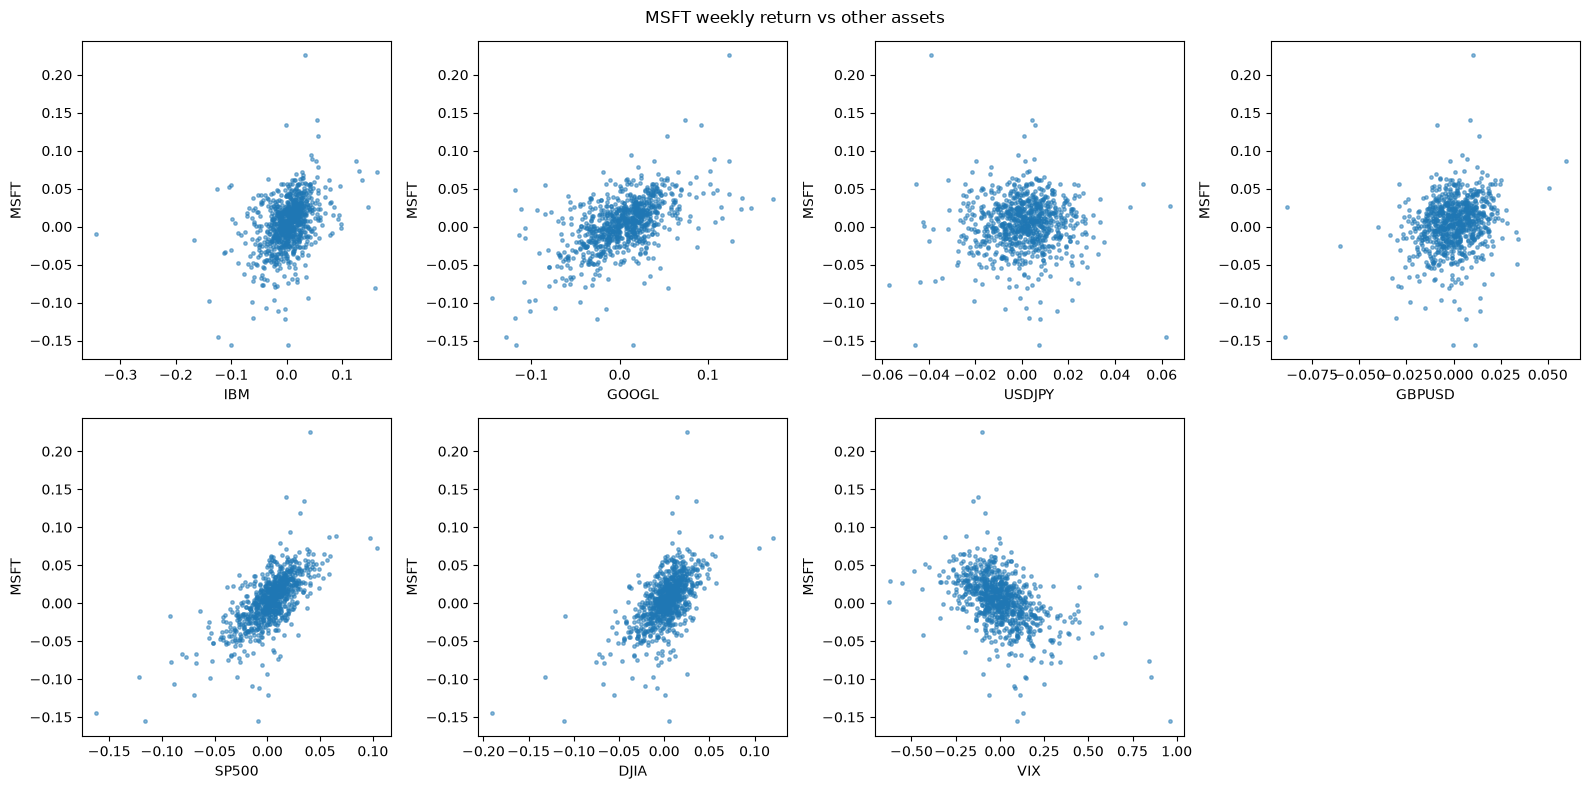

In [8]:
# 6. Scatter of MSFT vs each asset
others = [c for c in weekly.columns if c != "MSFT"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, others):
    ax.scatter(weekly[col], weekly["MSFT"], s=6, alpha=0.5)
    ax.set_xlabel(col); ax.set_ylabel("MSFT")
for ax in axes.flat[len(others):]:
    ax.axis("off")
plt.suptitle("MSFT weekly return vs other assets")
plt.tight_layout(); plt.savefig("figures/04_scatter.png", dpi=120); plt.show()

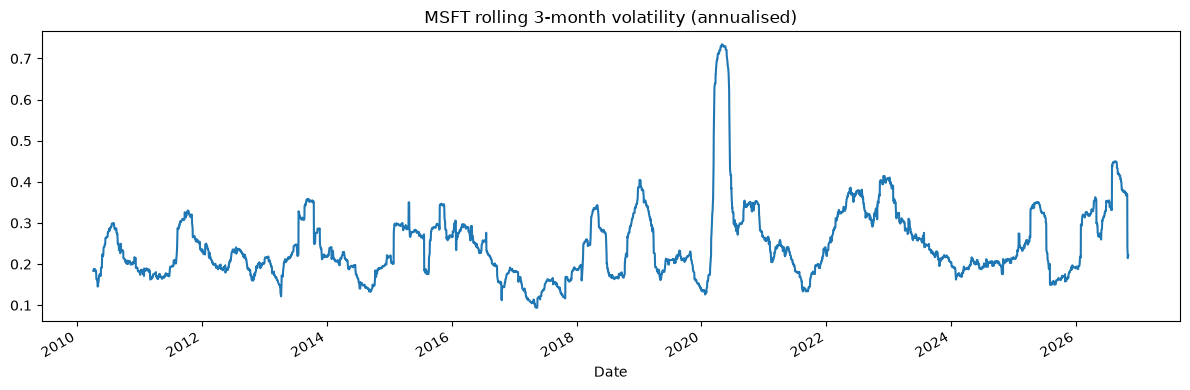

In [9]:
# 7. Rolling volatility of MSFT (annualised)
daily = np.log(prices["MSFT"]).diff()
(daily.rolling(63).std() * np.sqrt(252)).plot(figsize=(12, 4))
plt.title("MSFT rolling 3-month volatility (annualised)")
plt.tight_layout(); plt.savefig("figures/05_rolling_vol.png", dpi=120); plt.show()

In [10]:
# 8. Stationarity: prices vs returns (ADF test, p < 0.05 means stationary)
print("\nADF test p-values")
print(f"  MSFT price  : {adfuller(prices['MSFT'])[1]:.4f}")
print(f"  MSFT return : {adfuller(weekly['MSFT'])[1]:.4f}")

print("\nCharts saved in figures/")


ADF test p-values
  MSFT price  : 0.9875
  MSFT return : 0.0000

Charts saved in figures/
